# Semana 1: carga y reporte de Fast_Food_Restaurants

En este notebook se construye un flujo completo de trabajo:

1. Configurar la ruta del proyecto para importar las clases reutilizables.
2. Cargar `Fast_Food_Restaurants` desde Hugging Face.
3. Obtener un `DataFrame` de pandas y revisar su estructura.
4. Generar un reporte en pantalla y guardarlo en un archivo `.txt`.

Ejecuta las celdas en orden. Si el dataset requiere autenticación, inicia sesión previamente con `hf auth login`.

## 1. Preparar el entorno e importar la clase de carga

El notebook puede ejecutarse desde distintas carpetas. Por eso se buscan los directorios padres hasta encontrar `src/clases_po` y se agrega `src` a `sys.path`. Así se puede importar `HFDatasetLoader` sin instalar el proyecto como paquete.

In [5]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "src" / "clases_po").exists():
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT / "src"))

from clases_po import HFDatasetLoader

c:\Users\Usuario\Documents\Developers\PI3_2026Q4_Mary_Santi_Esteban\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Configurar el dataset y la salida

`dataset_name` identifica el repositorio en Hugging Face y `split="train"` indica la división que se descargará. El parámetro `filename` hace que el `DataFrame` también se guarde como CSV en `src/sincronicas/datos/` cuando el notebook se ejecuta desde esa carpeta.

In [6]:
loader = HFDatasetLoader(
    dataset_name="millat/e-commerce-orders",
    split="train",
    filename="datos/e-commerce-orders.csv",
)

## 3. Descargar el dataset y crear el DataFrame

El método `load()` descarga el dataset, lo convierte a `pandas.DataFrame` y lo asigna a la variable `df`. La expresión `df.head()` muestra las primeras filas para comprobar que la carga fue exitosa.

In [7]:
df = loader.load()
df.head()

,order_id,customer_id,product_id,category,price,quantity,order_date,shipping_date,delivery_status,payment_method,device_type,channel,shipping_address,billing_address,customer_segment
0,b8ec9f86-5919-4b71-a5f7-945e7c0a3db0,2031,845,Books,45.95,4,2024-04-20 14:59:58.897063,2024-04-27 14:59:58.897063,Shipped,PayPal,Mobile,Paid Search,"976 Kevin Station, Davidmouth, Hawaii 92563","38182 Ariel Expressway, Campbellland, Oklahoma...",VIP
1,5ea92c47-c5b2-4bdd-8a50-d77efd77ec89,2350,995,Electronics,403.17,3,2024-04-20 14:59:58.897063,2024-04-22 14:59:58.897063,Delivered,PayPal,Mobile,Paid Search,"72166 Cunningham Crescent, East Nicholasside, ...","38199 Edwin Plain, Johnborough, Maine 81826",Returning
2,5cc48ce0-2c6d-4448-af3f-96f8a910d45b,1818,997,Beauty,317.45,2,2024-04-20 14:59:58.897063,2024-04-27 14:59:58.897063,Shipped,Credit Card,Mobile,Email,"2446 Johnson Junctions, Lynchtown, Minnesota 7...","58086 Smith Stream Suite 994, Lake Pamelabury,...",Returning
3,74d5c0f4-53f0-4367-a5c5-baaa114c2d9f,472,385,Home,24.08,3,2024-04-20 14:59:58.897063,2024-04-24 14:59:58.897063,Shipped,PayPal,Tablet,Social,"3113 Jessica Knolls, North Joshuafort, Alabama...","484 Palmer Harbors Apt. 866, Dustintown, Nebra...",VIP
4,7a630323-8ac8-406e-875a-4bcdead440ab,1075,31,Clothing,494.90,1,2024-04-20 14:59:58.897063,2024-04-25 14:59:58.897063,Delivered,PayPal,Tablet,Organic,"58196 Burgess Heights Suite 315, Douglasland, ...","67094 Schaefer Villages Suite 369, Douglasches...",VIP


In [8]:
df.shape

(10000, 15)

## 4. Revisar la estructura del DataFrame

Esta celda realiza una revisión inicial: cuenta filas y columnas y muestra el tipo de cada columna junto con información de memoria y valores no nulos. Esta inspección ayuda a detectar problemas antes de analizar los datos.

In [9]:
print(f"Filas: {len(df)}")
print(f"Columnas: {len(df.columns)}")
df.info()

Filas: 10000
Columnas: 15
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   order_id          10000 non-null  str    
 1   customer_id       10000 non-null  int64  
 2   product_id        10000 non-null  int64  
 3   category          10000 non-null  str    
 4   price             10000 non-null  float64
 5   quantity          10000 non-null  int64  
 6   order_date        10000 non-null  str    
 7   shipping_date     10000 non-null  str    
 8   delivery_status   10000 non-null  str    
 9   payment_method    10000 non-null  str    
 10  device_type       10000 non-null  str    
 11  channel           10000 non-null  str    
 12  shipping_address  10000 non-null  str    
 13  billing_address   10000 non-null  str    
 14  customer_segment  10000 non-null  str    
dtypes: float64(1), int64(3), str(11)
memory usage: 3.4 MB


## 1.1 Preparar el entorno e importar las clases

El notebook puede ejecutarse desde distintas carpetas. Por eso se buscan los directorios padres hasta encontrar `src/clases_po` y se agrega `src` a `sys.path`. Así se pueden importar las clases sin instalar el proyecto como paquete.

In [10]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "src" / "clases_po").exists():
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT / "src"))

from clases_po import HFDatasetLoader, Reportes
from clases_po import PreprocesadorEcommerce, EnriquecedorEcommerce, LLMNvidia
from clases_po import AnalisisBase, AnalisisEcommerce, GraficosBase, GraficosEcommerce
from clases_po import RegresionLineal, ClasificadorTexto

import pandas as pd
from IPython.display import display

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

## 1.2 Configurar el dataset y la salida

`dataset_name` identifica el repositorio en Hugging Face y `split="train"` indica la división que se descargará. El parámetro `filename` hace que el `DataFrame` también se guarde como CSV en `src/sincronicas/datos/` cuando el notebook se ejecuta desde esa carpeta.

In [11]:
loader = HFDatasetLoader(
    dataset_name="millat/e-commerce-orders",
    split="train",
    filename="datos/e-commerce-orders.csv",
)
df = loader.load()
df.shape

(10000, 15)

---
# PARTE 2 · Preprocesamiento y estandarización (clase `PreprocesadorEcommerce`)

El dataset `millat/e-commerce-orders` tiene **10.000 pedidos** (una línea por pedido) entre el 20/04/2024 y el 19/04/2025. `filas_clase=None` usa todas las filas; con un número (por ejemplo `filas_clase=1700`) se trabaja solo con las primeras filas para pruebas rápidas.

## 2.1 Diagnóstico de tipos

Equivale a `ESTEXTO`, `ESNUMERO`, `CONTARA` y `CONTAR` por columna.

In [12]:
pre = PreprocesadorEcommerce(filas_clase=None)

df_base = pre.recortar(df)
pre.diagnosticar(df_base)

,columna,tipo_actual,ejemplo,no_vacíos (CONTARA),convertibles_a_número,¿es número? (ESNUMERO)
0,order_id,str,b8ec9f86-5919-4b71-a5f7-945e7c0a3db0,10000,0,False
1,customer_id,int64,2031,10000,10000,True
2,product_id,int64,845,10000,10000,True
3,category,str,Books,10000,0,False
4,price,float64,45.95,10000,10000,True
5,quantity,int64,4,10000,10000,True
6,order_date,str,2024-04-20 14:59:58.897063,10000,0,False
7,shipping_date,str,2024-04-27 14:59:58.897063,10000,0,False
8,delivery_status,str,Shipped,10000,0,False
9,payment_method,str,PayPal,10000,0,False


**Lectura:** `order_date` y `shipping_date` llegan como **texto**, `order_id` es un código UUID en texto, los identificadores de cliente y producto son enteros, y `category`, `device_type`, `channel` y `customer_segment` son texto libre sin orden.

## 2.2 Diccionario de columnas

In [13]:
pre.diccionario()

,columna,qué significa,tipo de variable,tipo en pandas
0,order_id,Identificador único del pedido,Cualitativa nominal,string
1,customer_id,Identificador del cliente,Cuantitativa discreta,int64
2,product_id,Identificador del producto,Cuantitativa discreta,int64
3,quantity,Cantidad de unidades,Cuantitativa discreta,int64
4,order_date,Fecha y hora del pedido,Cuantitativa (tiempo),datetime64
5,shipping_date,Fecha y hora del envío,Cuantitativa (tiempo),datetime64
6,price,Precio unitario,Cuantitativa continua,"float64 (moneda, 2 dec.)"
7,order_value,Cantidad × precio unitario,Cuantitativa continua,"float64 (moneda, 2 dec.)"
8,device_type,Dispositivo utilizado,Cualitativa nominal,category
9,category,Categoría del producto,Cualitativa nominal,category


## 2.3 Convertir tipos y agregar columnas calculadas

| Paso | Qué hace | Método de la clase |
|---|---|---|
| Números, fechas y categorías | Convierte `quantity`, `price`, `order_date`, `shipping_date`; crea `order_value` (cantidad × precio), `shipping_days` y `order_time`; `device_type` y `category` pasan a categorías | `convertir_tipos()` |
| Columnas calculadas | `total_calculado`, `verificacion`, `dia_semana`, `hora`, `nuevo_pedido` | `agregar_columnas_calculadas()` |
| Los dos pasos seguidos | | `procesar()` |

In [14]:
datos = pre.procesar(df)
datos.head()

,order_id,customer_id,product_id,category,price,quantity,order_date,shipping_date,delivery_status,payment_method,device_type,channel,shipping_address,billing_address,customer_segment,order_time,fecha_hora,shipping_days,order_value,total_calculado,verificacion,dia_semana,hora,nuevo_pedido
0,b8ec9f86-5919-4b71-a5f7-945e7c0a3db0,2031,845,Books,45.95,4,2024-04-20 14:59:58.897063,2024-04-27 14:59:58.897063,Shipped,PayPal,Mobile,Paid Search,"976 Kevin Station, Davidmouth, Hawaii 92563","38182 Ariel Expressway, Campbellland, Oklahoma...",VIP,14:59:58.897063,2024-04-20 14:59:58.897063,7.0,183.80,183.80,OK,sábado,14,1
1,5ea92c47-c5b2-4bdd-8a50-d77efd77ec89,2350,995,Electronics,403.17,3,2024-04-20 14:59:58.897063,2024-04-22 14:59:58.897063,Delivered,PayPal,Mobile,Paid Search,"72166 Cunningham Crescent, East Nicholasside, ...","38199 Edwin Plain, Johnborough, Maine 81826",Returning,14:59:58.897063,2024-04-20 14:59:58.897063,2.0,1209.51,1209.51,OK,sábado,14,1
2,5cc48ce0-2c6d-4448-af3f-96f8a910d45b,1818,997,Beauty,317.45,2,2024-04-20 14:59:58.897063,2024-04-27 14:59:58.897063,Shipped,Credit Card,Mobile,Email,"2446 Johnson Junctions, Lynchtown, Minnesota 7...","58086 Smith Stream Suite 994, Lake Pamelabury,...",Returning,14:59:58.897063,2024-04-20 14:59:58.897063,7.0,634.90,634.90,OK,sábado,14,1
3,74d5c0f4-53f0-4367-a5c5-baaa114c2d9f,472,385,Home,24.08,3,2024-04-20 14:59:58.897063,2024-04-24 14:59:58.897063,Shipped,PayPal,Tablet,Social,"3113 Jessica Knolls, North Joshuafort, Alabama...","484 Palmer Harbors Apt. 866, Dustintown, Nebra...",VIP,14:59:58.897063,2024-04-20 14:59:58.897063,4.0,72.24,72.24,OK,sábado,14,1
4,7a630323-8ac8-406e-875a-4bcdead440ab,1075,31,Clothing,494.90,1,2024-04-20 14:59:58.897063,2024-04-25 14:59:58.897063,Delivered,PayPal,Tablet,Organic,"58196 Burgess Heights Suite 315, Douglasland, ...","67094 Schaefer Villages Suite 369, Douglasches...",VIP,14:59:58.897063,2024-04-20 14:59:58.897063,5.0,494.90,494.90,OK,sábado,14,1


In [15]:
datos.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 24 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   order_id          10000 non-null  string        
 1   customer_id       10000 non-null  Int64         
 2   product_id        10000 non-null  Int64         
 3   category          10000 non-null  category      
 4   price             10000 non-null  float64       
 5   quantity          10000 non-null  int64         
 6   order_date        10000 non-null  datetime64[us]
 7   shipping_date     10000 non-null  datetime64[us]
 8   delivery_status   10000 non-null  string        
 9   payment_method    10000 non-null  string        
 10  device_type       10000 non-null  category      
 11  channel           10000 non-null  string        
 12  shipping_address  10000 non-null  string        
 13  billing_address   10000 non-null  string        
 14  customer_segment  10000 non-null  

## 2.4 Validaciones de calidad

Con `filas_clase=None` también se comparan los totales esperados del dataset: 10.000 filas, 10.000 pedidos y 2.713 clientes.

In [16]:
pre.validar(datos)

✔ Sin valores nulos tras convertir 
✔ Sin filas duplicadas 
✔ order_value = quantity × price (0 filas a revisar)
✔ Fechas válidas de pedido y envío 
✔ Filas = 10,000 ? 10,000
✔ Pedidos = 10,000 ? 10,000
✔ Clientes = 2,713 ? 2,713

Rango de fechas: 20/04/2024 a 19/04/2025 (365 días; el último tiene 27 líneas)


True

> **Nota:** todos los pedidos tienen la misma hora del día (14:59:58), así que `hora` vale 14 en las 10.000 filas. Por eso el análisis por hora no aporta información en este dataset y se omite en las Partes 3 y 4.

---
# PARTE 3 · Análisis descriptivo con los datos originales (sin enriquecer)

Antes de enriquecer se analiza la base tal como viene: **10.000 pedidos de una tienda en línea, del 20/04/2024 al 19/04/2025**.

- `AB = AnalisisBase(datos, producto_elegido=845)` calcula las tablas. `producto_elegido` es el `product_id` que se sigue día a día (equivale a la lista desplegable del Excel).
- `GB = GraficosBase(AB)` dibuja los gráficos y el dashboard.

In [17]:
AB = AnalisisBase(datos, producto_elegido=845)
GB = GraficosBase(AB)
print("Periodo analizado:", AB.periodo())

Periodo analizado: 20/04/2024 a 19/04/2025 (365 días)


## 3.1 Fórmulas básicas

Cada fórmula de Excel con su equivalente en pandas y el resultado: operaciones con una fila (la fila 185 de la hoja de datos), funciones de resumen, valores únicos y condiciones.

In [18]:
AB.formulas_basicas(fila_excel=185)

,#,qué quiero saber,fórmula en Excel,equivalente en pandas,resultado
0,1,Multiplicar: total de la línea,=Datos!D185*Datos!G185,V.quantity[i] * V.price[i],207.01
1,2,Dividir: precio de cada producto,=Datos!H185/Datos!D185,V.order_value[i] / V.quantity[i],207.01
2,3,Sumar: productos en dos líneas,=Datos!D185+Datos!D186,V.quantity[i] + V.quantity[i+1],3.0
3,4,Restar: precio más alto − más bajo,=MAX(G)-MIN(G),V.price.max() - V.price.min(),494.87
4,5,Redondear el precio promedio,=REDONDEAR(PROMEDIO(G);2),"round(V.price.mean(), 2)",252.55
5,6,Ventas totales,=SUMA(H),V.order_value.sum(),5334932.86
6,7,Unidades vendidas,=SUMA(D),V.quantity.sum(),21247.0
7,8,Líneas con número,=CONTAR(H),V.order_value.count(),10000.0
8,9,Líneas con nombre de producto,=CONTARA(L),V.product_id.notna().sum(),10000.0
9,10,Celdas vacías en la categoría,=CONTAR.BLANCO(J),V.category.isna().sum(),0.0


## 3.2 Resumen del negocio

In [19]:
display(AB.estilo(AB.resumen_total()))

,Empresa
Ventas totales,"5,334,932.86"
Unidades vendidas,"21,247.00"
Líneas de pedido,"10,000.00"
Pedidos,"10,000.00"
Ticket promedio,533.49
Unidades por pedido,2.12
Precio promedio por producto,251.09
Días con ventas,365.00
Venta promedio por día,"14,616.25"
Clientes únicos,"2,713.00"


## 3.3 Medidas de las variables cuantitativas

In [20]:
display(AB.medidas_variables().round(3))
print(AB.lectura_media_mediana())

,quantity,price,order_value,valor_pedido
n (datos),10000.000,10000.000,10000.000,10000.000
Suma,21247.000,2525506.810,5334932.860,5334932.860
Media,2.125,252.551,533.493,533.493
Mediana,2.000,252.910,395.625,395.625
Moda,1.000,65.510,226.530,226.530
Mínimo,1.000,5.060,5.100,5.100
Máximo,9.000,499.930,4224.240,4224.240
Rango,8.000,494.870,4219.140,4219.140
Desviación estándar,1.254,141.394,465.566,465.566
Coef. de variación,0.590,0.560,0.873,0.873


Lectura: en order_value la media ($533.49) es mayor que la mediana ($395.62): unas pocas líneas con varias productos jalan el promedio hacia arriba (sesgo a la derecha).


## 3.4 Frecuencias por dispositivo y por categoría

`device_type` es una variable ordinal (Mobile < Tablet < Desktop, según el orden de la clase) y `category` es nominal.

Por dispositivo


,líneas,% líneas,% acumulado,productos,ventas,% ventas,precio_unit_promedio
Mobile,"3,278",32.8%,32.8%,"6,926","$1,740,201.96",32.6%,$251.44
Tablet,"3,339",33.4%,66.2%,"7,096","$1,768,153.28",33.1%,$251.90
Desktop,"3,383",33.8%,100.0%,"7,225","$1,826,577.62",34.2%,$254.27
Total,"10,000",100.0%,—,"21,247","$5,334,932.86",100.0%,$252.55


Por categoría


,líneas,% líneas,% acumulado,productos,ventas,% ventas,precio_unit_promedio
Beauty,"1,682",16.8%,16.8%,"3,617","$888,823.19",16.7%,$247.65
Books,"1,625",16.2%,33.1%,"3,404","$862,484.56",16.2%,$255.34
Clothing,"1,620",16.2%,49.3%,"3,392","$863,629.45",16.2%,$256.39
Electronics,"1,694",16.9%,66.2%,"3,586","$910,153.11",17.1%,$255.77
Home,"1,713",17.1%,83.3%,"3,696","$921,394.85",17.3%,$250.30
Toys,"1,666",16.7%,100.0%,"3,552","$888,447.70",16.7%,$250.09
Total,"10,000",100.0%,—,"21,247","$5,334,932.86",100.0%,$252.55


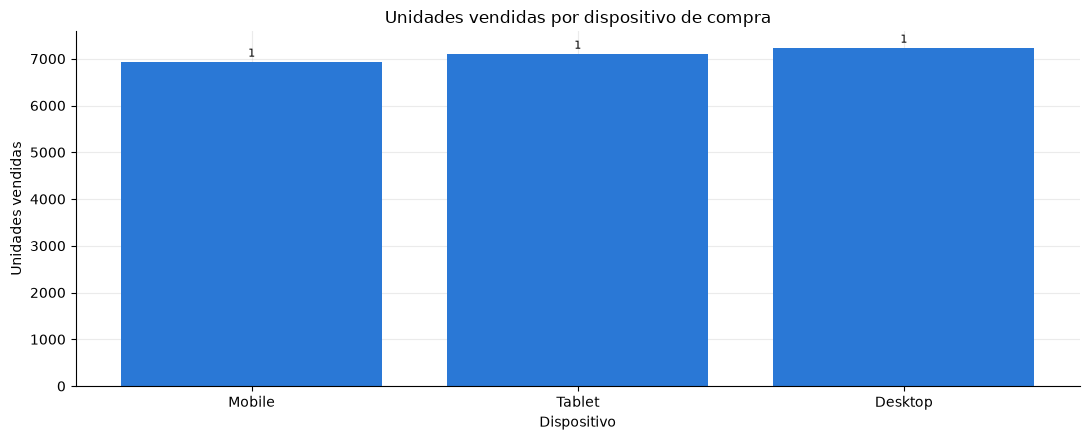

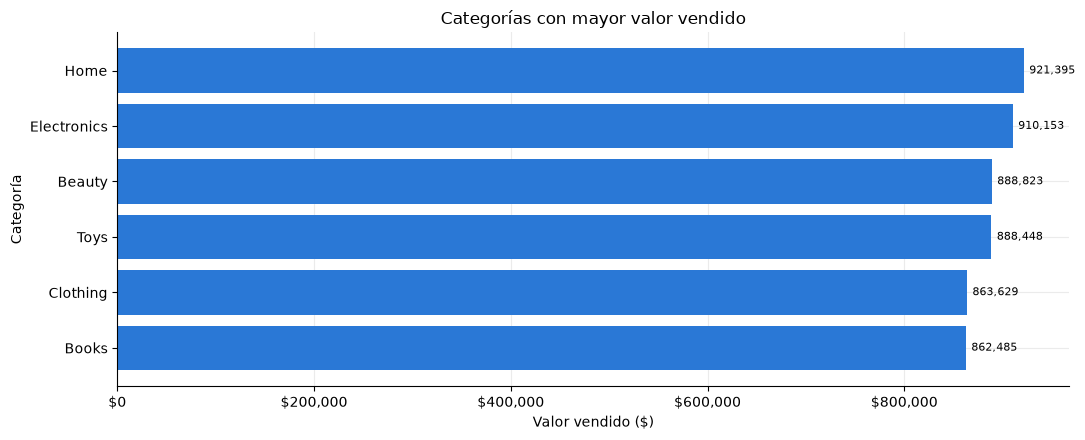

In [21]:
print("Por dispositivo")
display(AB.estilo(AB.frecuencias("device_type")))
print("Por categoría")
display(AB.estilo(AB.frecuencias("category")))
GB.dispositivos()
GB.categorias()

## 3.5 Distribución de `order_value`

,líneas,% líneas
order_value,,
$0 o más,"1,146",11.5%
$100 o más,"1,278",12.8%
$200 o más,"1,283",12.8%
$300 o más,"1,362",13.6%
$400 o más,"1,296",13.0%
$500 o más,"3,635",36.4%


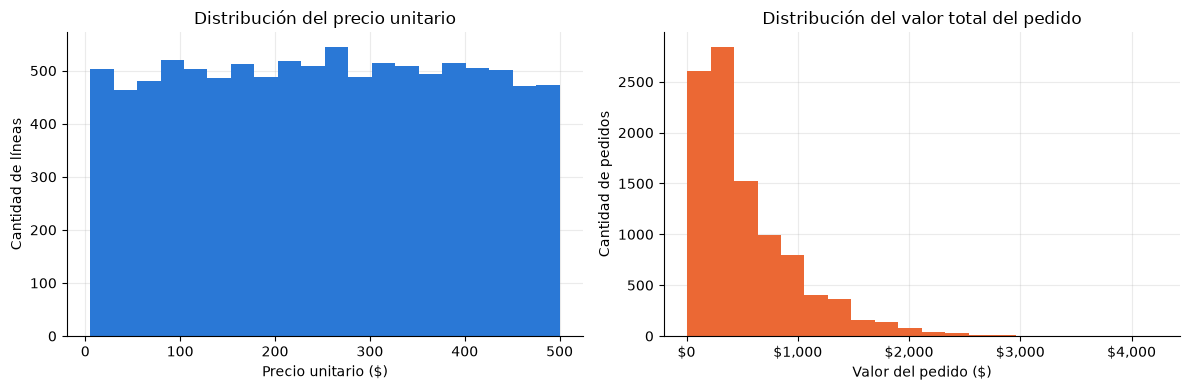

In [22]:
display(AB.estilo(AB.distribucion_precio()))
GB.histogramas()

## 3.6 Ventas por día y producto elegido

Para seguir otro producto: `AB.producto_elegido = 995`. La tabla diaria tiene 365 filas; se muestran los primeros 10 días.

,order_date,día,líneas,productos,pedidos,ventas,ticket promedio,% ventas,ventas producto elegido
0,20/04/2024,sábado,29,56,29,"$10,622.56",$366.30,0.2%,$183.80
1,21/04/2024,domingo,29,75,29,"$20,477.08",$706.11,0.4%,$0.00
2,22/04/2024,lunes,39,83,39,"$16,417.46",$420.96,0.3%,$0.00
3,23/04/2024,martes,23,47,23,"$10,129.70",$440.42,0.2%,$0.00
4,24/04/2024,miércoles,29,62,29,"$16,700.75",$575.89,0.3%,$0.00
5,25/04/2024,jueves,32,70,32,"$16,007.24",$500.23,0.3%,$0.00
6,26/04/2024,viernes,38,77,38,"$20,501.45",$539.51,0.4%,$0.00
7,27/04/2024,sábado,32,54,32,"$10,704.87",$334.53,0.2%,$0.00
8,28/04/2024,domingo,32,69,32,"$18,444.98",$576.41,0.3%,$0.00
9,29/04/2024,lunes,25,50,25,"$14,220.66",$568.83,0.3%,$0.00


Día con más ventas: 12/08/2024 (lunes) → $24,764.74
Día con menos ventas: 21/11/2024 (jueves) → $5,475.59
845: ventas $6,354.50; su mejor día 26/05/2024


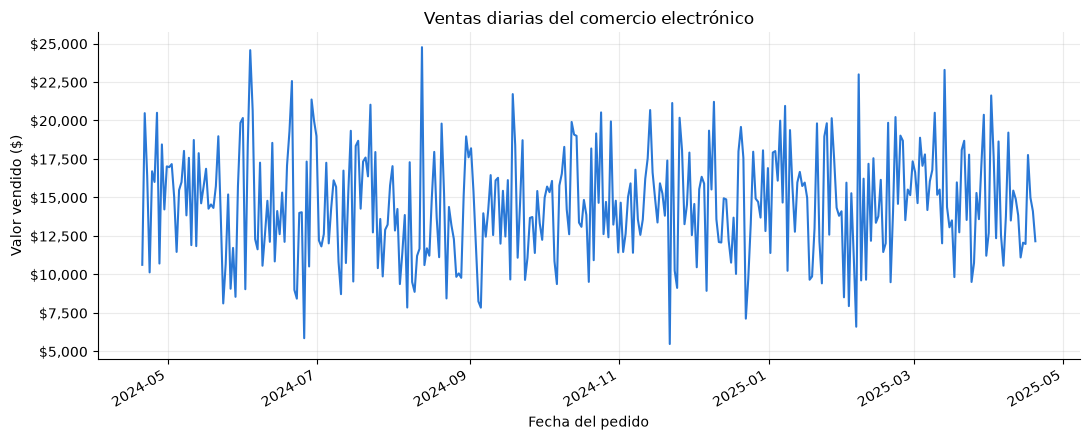

In [23]:
ventas_dia = AB.ventas_por_dia().reset_index().assign(
    order_date=lambda x: x["order_date"].dt.strftime("%d/%m/%Y"))
display(AB.estilo(ventas_dia.head(10)))
print(AB.lectura_dias())
GB.ventas_por_dia()

Venta promedio por día de la semana (cada día aparece unas 52 veces en el año)


,días en el periodo,ventas,venta promedio por día
dia_semana,,,
lunes,52,"$779,608.29","$14,992.47"
martes,52,"$753,413.59","$14,488.72"
miércoles,52,"$761,386.10","$14,642.04"
jueves,52,"$776,706.80","$14,936.67"
viernes,52,"$769,844.55","$14,804.70"
sábado,53,"$740,206.99","$13,966.17"
domingo,52,"$753,766.54","$14,495.51"


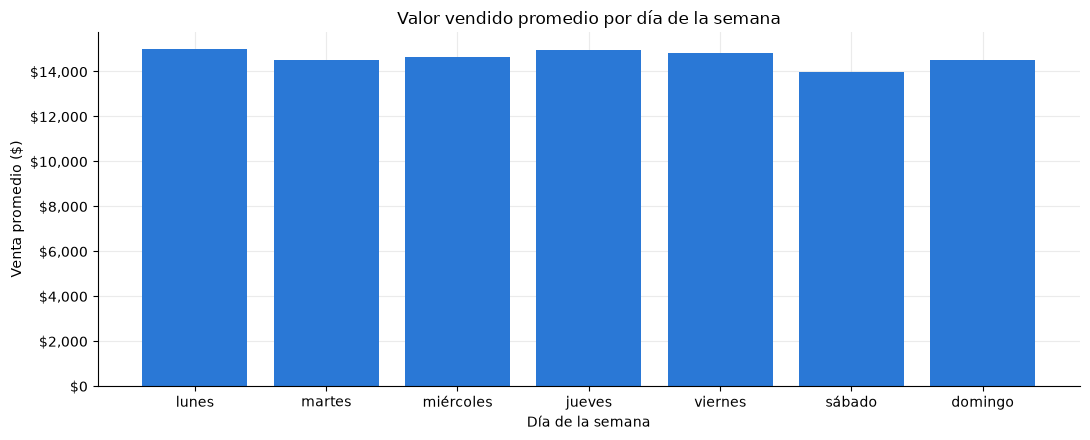

In [24]:
print("Venta promedio por día de la semana (cada día aparece unas 52 veces en el año)")
display(AB.estilo(AB.dia_semana_resumen()))
GB.dia_semana()

## 3.7 Dos variables a la vez: categoría × dispositivo

,ventas Mobile,ventas Tablet,ventas Desktop,ventas Total
category,,,,
Beauty,"$293,857.84","$293,434.96","$301,530.39","$888,823.19"
Books,"$275,839.59","$295,641.44","$291,003.53","$862,484.56"
Clothing,"$289,667.30","$281,209.12","$292,753.03","$863,629.45"
Electronics,"$269,226.53","$306,598.90","$334,327.68","$910,153.11"
Home,"$316,523.57","$299,966.11","$304,905.17","$921,394.85"
Toys,"$295,087.13","$291,302.75","$302,057.82","$888,447.70"
Total,"$1,740,201.96","$1,768,153.28","$1,826,577.62","$5,334,932.86"


device_type,Mobile,Tablet,Desktop,Total
category,,,,
Beauty,556,548,578,1682
Books,515,553,557,1625
Clothing,538,538,544,1620
Electronics,525,568,601,1694
Home,590,573,550,1713
Toys,554,559,553,1666
Total,3278,3339,3383,10000


Lectura: la combinación que más vende es Electronics Desktop ($334,327.68).


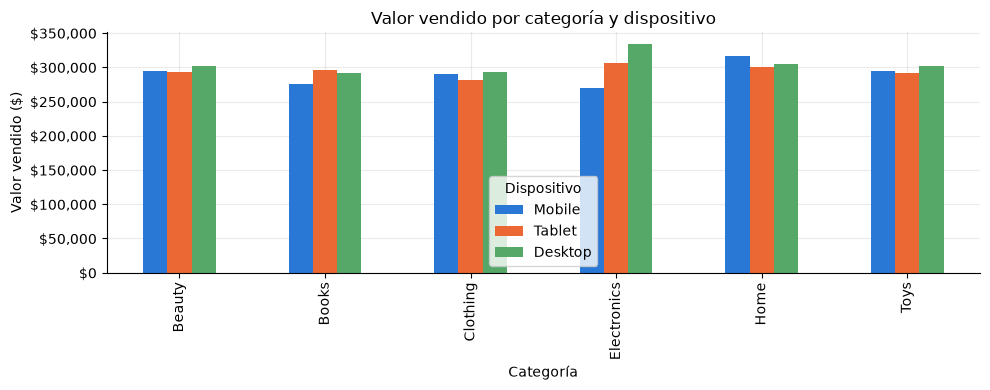

In [25]:
display(AB.estilo(AB.categoria_x_dispositivo("ventas")))
display(AB.categoria_x_dispositivo("lineas"))
print(AB.combinacion_lider())
GB.categoria_dispositivo()

## 3.8 Tres condiciones: un día, una categoría y un dispositivo

In [26]:
pd.DataFrame({
    "20/04/2024 · Beauty · Mobile": AB.consulta(fecha="2024-04-20", categoria="Beauty", dispositivo="Mobile"),
    "21/04/2024 · Electronics · Desktop": AB.consulta(fecha="2024-04-21", categoria="Electronics", dispositivo="Desktop"),
    "22/04/2024 · Beauty · Desktop": AB.consulta(fecha="2024-04-22", categoria="Beauty", dispositivo="Desktop"),
})

,20/04/2024 · Beauty · Mobile,21/04/2024 · Electronics · Desktop,22/04/2024 · Beauty · Desktop
Ventas,1793.04,3205.67,578.32
Unidades,11.00,14.00,4.00
Líneas,6.00,5.00,2.00
Precio promedio,190.06,291.40,131.55


## 3.9 Ranking de productos por ventas

,posición,categoría,productos,ventas,% ventas,% acumulado
product_id,,,,,,
995,1,Electronics,47,"$15,610.51",0.3%,0.3%
730,2,Toys,50,"$13,774.48",0.3%,0.6%
955,3,Home,43,"$13,480.56",0.3%,0.8%
585,4,Books,37,"$13,397.68",0.3%,1.1%
370,5,Beauty,48,"$13,234.77",0.2%,1.3%
957,6,Toys,42,"$13,012.81",0.2%,1.5%
803,7,Electronics,46,"$12,709.85",0.2%,1.8%
974,8,Electronics,45,"$12,566.78",0.2%,2.0%
642,9,Clothing,49,"$12,287.90",0.2%,2.3%


Pareto: 653 de 999 productos generan el 80 % de las ventas.


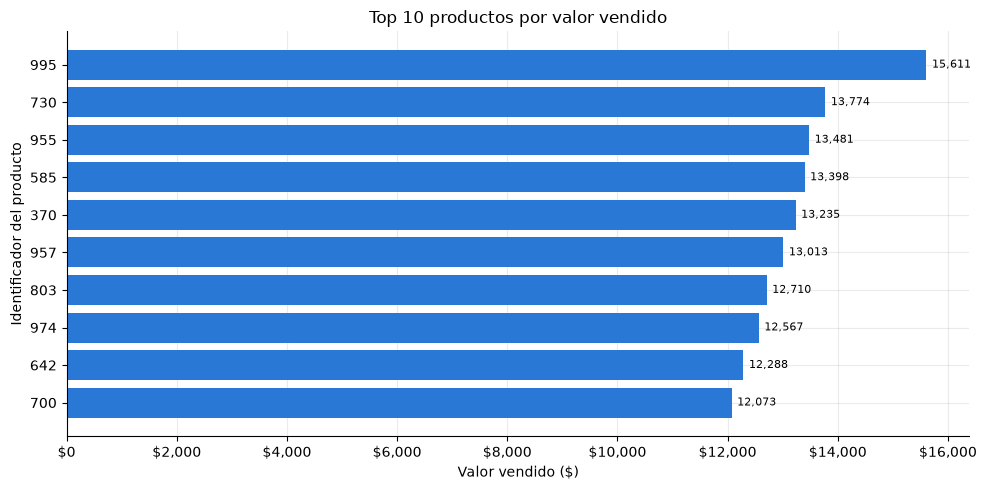

In [27]:
ranking_base = AB.ranking_productos()
display(AB.estilo(ranking_base.head(10)))
print(f"Pareto: {AB.productos_para_80()} de {len(ranking_base)} productos generan el 80 % de las ventas.")
GB.top_productos(10)

## 3.10 Tabla dinámica

In [28]:
print("Filtro día_semana: - all -")
display(AB.estilo(AB.tabla_dinamica()))
print("Filtro día_semana: sábado")
AB.estilo(AB.tabla_dinamica(dia_semana="sábado"))

Filtro día_semana: - all -


,suma Mobile,suma Tablet,suma Desktop,suma Total
category,,,,
Beauty,"$293,857.84","$293,434.96","$301,530.39","$888,823.19"
Books,"$275,839.59","$295,641.44","$291,003.53","$862,484.56"
Clothing,"$289,667.30","$281,209.12","$292,753.03","$863,629.45"
Electronics,"$269,226.53","$306,598.90","$334,327.68","$910,153.11"
Home,"$316,523.57","$299,966.11","$304,905.17","$921,394.85"
Toys,"$295,087.13","$291,302.75","$302,057.82","$888,447.70"
Total,"$1,740,201.96","$1,768,153.28","$1,826,577.62","$5,334,932.86"


Filtro día_semana: sábado


,suma Mobile,suma Tablet,suma Desktop,suma Total
category,,,,
Beauty,"$50,461.83","$39,599.00","$52,558.79","$142,619.62"
Books,"$30,462.33","$30,377.82","$40,983.98","$101,824.13"
Clothing,"$31,074.16","$40,349.97","$39,224.36","$110,648.49"
Electronics,"$42,978.03","$32,460.50","$53,879.55","$129,318.08"
Home,"$49,066.25","$44,973.07","$46,831.09","$140,870.41"
Toys,"$43,266.38","$32,992.12","$38,667.76","$114,926.26"
Total,"$247,308.98","$220,752.48","$272,145.53","$740,206.99"


## 3.11 Dashboard

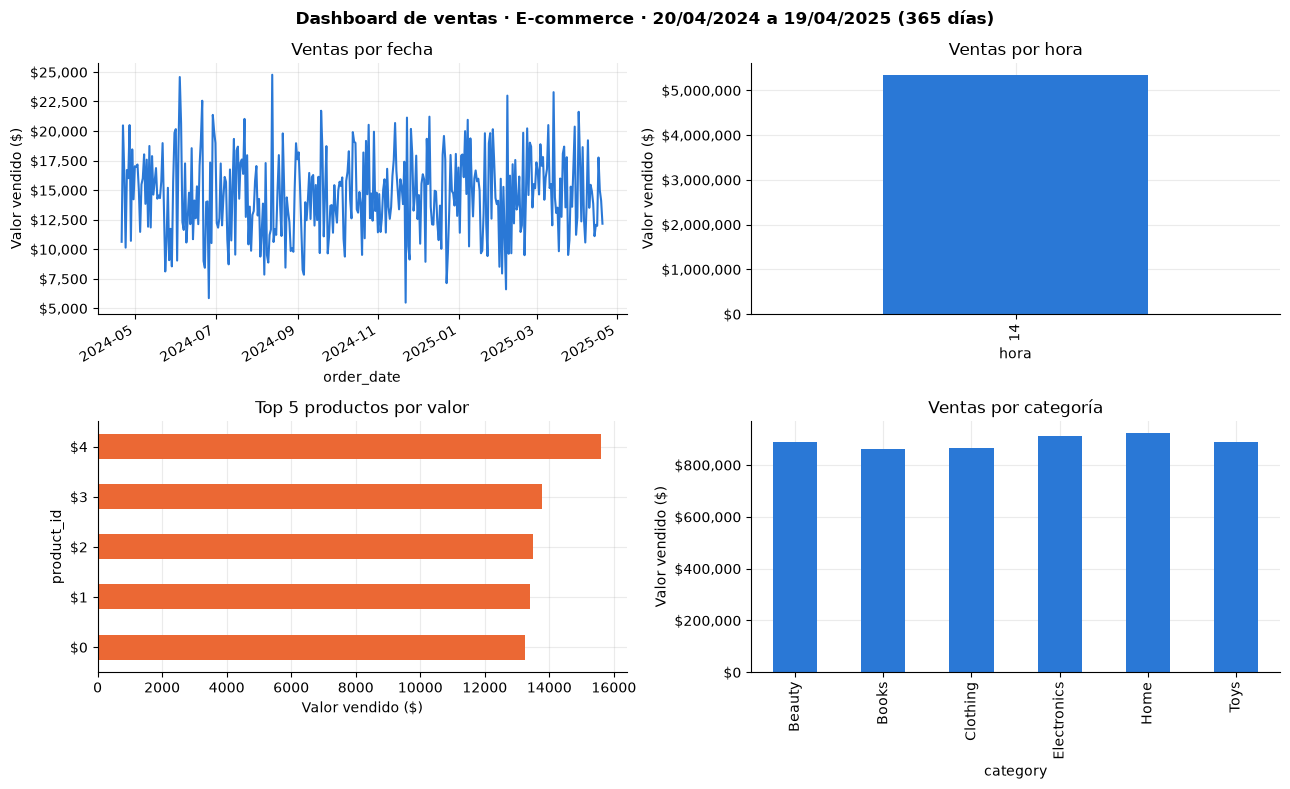

{'VENTAS': '$5,334,932.86',
 'PRODUCTOS': '21,247',
 'PEDIDOS': '10,000',
 'CLIENTES': '2,713',
 'PRECIO PROM./PRODUCTO': '$251.09',
 '% VENTAS TOTALES': '100.0%',
 'MEJOR DÍA': '12/08',
 'HORA PICO': '14:00',
 'PRODUCTO LÍDER': '995'}

In [29]:
GB.dashboard(titulo="Dashboard de ventas · E-commerce")

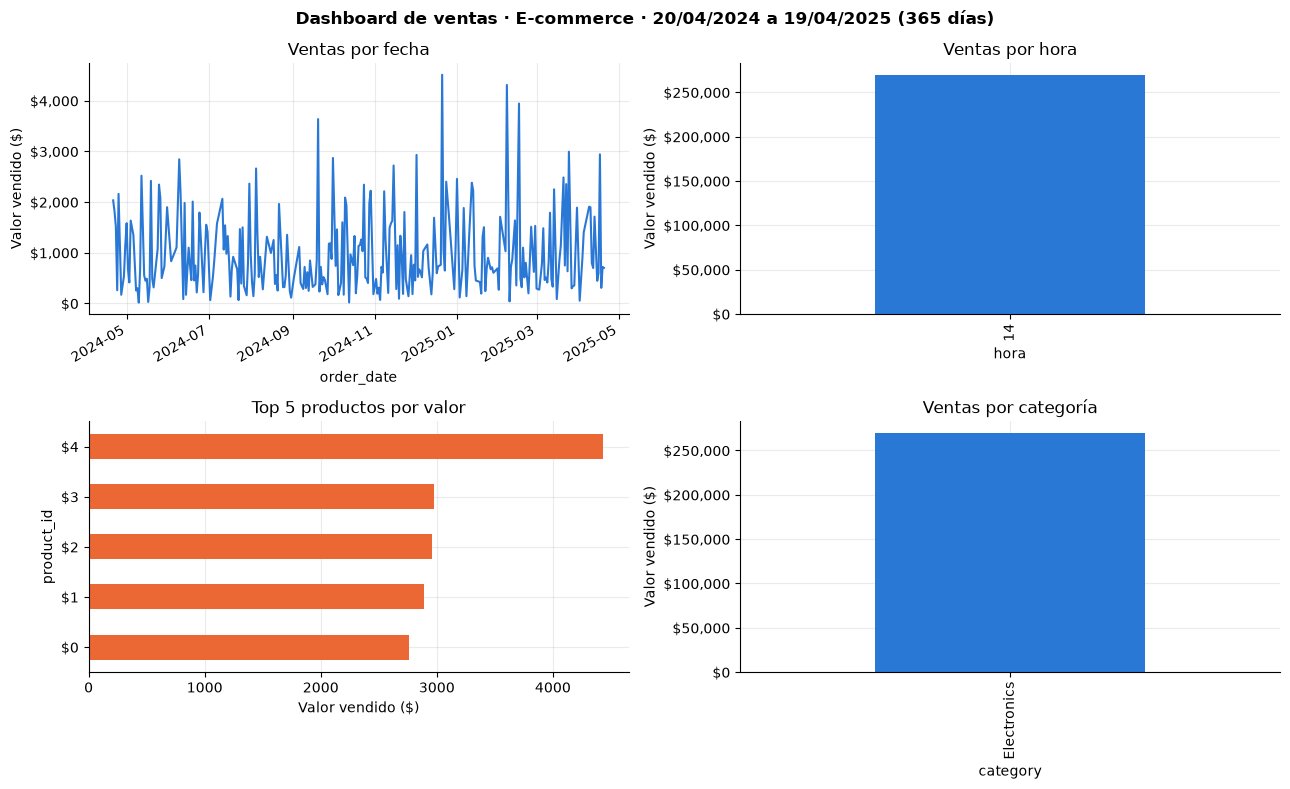

{'VENTAS': '$269,226.53',
 'PRODUCTOS': '1,079',
 'PEDIDOS': '525',
 'CLIENTES': '436',
 'PRECIO PROM./PRODUCTO': '$249.51',
 '% VENTAS TOTALES': '5.0%',
 'MEJOR DÍA': '20/12',
 'HORA PICO': '14:00',
 'PRODUCTO LÍDER': '12'}

In [30]:
GB.dashboard(categoria="Electronics", dispositivo="Mobile", titulo="Dashboard de ventas · E-commerce")

---
# PARTE 4 · Enriquecimiento (clases `EnriquecedorEcommerce` y `LLMNvidia`)

**Objetivo:** agregar al dataset variables de negocio derivadas de sus propias columnas, sin inventar entidades externas, y analizarlas por canal, segmento y estado de entrega.

| Nivel | Columnas nuevas |
|---|---|
| Pedido | `order_value` (recalculado), `shipping_days` (días entre pedido y envío), `delivery_delay` (`True` si `shipping_days` > 3) |
| Cliente | `customer_order_count` (pedidos del cliente), `customer_recurrente` (`True` si tiene más de un pedido) |
| Participación | `channel_sales_share` y `segment_sales_share` (parte del pedido dentro de las ventas de su canal y de su segmento) |

**Papel del LLM:** `EnriquecedorEcommerce` calcula todo con pandas. `LLMNvidia` se usa al final, de forma opcional, para redactar un resumen ejecutivo a partir de las tablas. Sin `NVIDIA_API_KEY` el notebook sigue funcionando y usa un resumen calculado.

## 4.1 Conexión con el LLM (opcional)

Para activarlo: `$env:NVIDIA_API_KEY = "nvapi-..."` en la terminal antes de abrir el notebook, y `pip install openai`.

In [31]:
from clases_po import LLMNvidia

In [32]:
llm = LLMNvidia(modelo="nvidia/nemotron-3-ultra-550b-a55b", pensar=False)
llm

LLMNvidia(modelo='nvidia/nemotron-3-ultra-550b-a55b', pensar=False, estado=activo)

In [42]:
conexion_ok = llm.probar_conexion()

Apoya decisiones operativas y tácticas inmediatas —como gestión de inventario, personal logístico, campañas promocionales y ajustes de precios— al revelar patrones históricos de demanda, estacionalidad, rendimiento de productos y comportamiento de compra.


## 4.2 Enriquecer el dataset

In [43]:
enr = EnriquecedorEcommerce(pre)
ventas_enr = enr.enriquecer(datos)

columnas_nuevas = ["order_value", "shipping_days", "delivery_delay", "customer_order_count",
                   "customer_recurrente", "channel_sales_share", "segment_sales_share"]
print(f"Filas: {len(ventas_enr):,} · Columnas: {len(datos.columns)} → {len(ventas_enr.columns)}")
ventas_enr[["order_id", "customer_id", "channel", "customer_segment"] + columnas_nuevas].head()

Filas: 10,000 · Columnas: 24 → 29


,order_id,customer_id,channel,customer_segment,order_value,shipping_days,delivery_delay,customer_order_count,customer_recurrente,channel_sales_share,segment_sales_share
0,b8ec9f86-5919-4b71-a5f7-945e7c0a3db0,2031,Paid Search,VIP,183.80,7.0,True,6,True,0.000135,0.000068
1,5ea92c47-c5b2-4bdd-8a50-d77efd77ec89,2350,Paid Search,Returning,1209.51,2.0,False,2,True,0.000891,0.000522
2,5cc48ce0-2c6d-4448-af3f-96f8a910d45b,1818,Email,Returning,634.90,7.0,True,3,True,0.000470,0.000274
3,74d5c0f4-53f0-4367-a5c5-baaa114c2d9f,472,Social,VIP,72.24,4.0,True,6,True,0.000053,0.000027
4,7a630323-8ac8-406e-875a-4bcdead440ab,1075,Organic,VIP,494.90,5.0,True,5,True,0.000390,0.000182


## 4.3 Validaciones del enriquecimiento

In [35]:
c = pre.check
ok = [
    c("Mismas filas que la base procesada", len(ventas_enr) == len(datos), f"({len(ventas_enr):,})"),
    c("Sin nulos en las columnas nuevas", ventas_enr[columnas_nuevas].isna().sum().sum() == 0),
    c("Ningún envío antes del pedido", (ventas_enr["shipping_days"] >= 0).all()),
    c("Participación por canal suma 100 % en cada canal",
      ventas_enr.groupby("channel")["channel_sales_share"].sum().round(6).eq(1).all()),
    c("Participación por segmento suma 100 % en cada segmento",
      ventas_enr.groupby("customer_segment")["segment_sales_share"].sum().round(6).eq(1).all()),
    c("Ventas totales iguales antes y después", round(ventas_enr["order_value"].sum(), 2) == round(datos["order_value"].sum(), 2)),
]
print("\nTodas las validaciones pasaron" if all(ok) else "\nRevisar las validaciones marcadas con ✘")

✔ Mismas filas que la base procesada (10,000)
✔ Sin nulos en las columnas nuevas 
✔ Ningún envío antes del pedido 
✔ Participación por canal suma 100 % en cada canal 
✔ Participación por segmento suma 100 % en cada segmento 
✔ Ventas totales iguales antes y después 

Todas las validaciones pasaron


## 4.4 Clientes: cuántos son recurrentes

`resumen_clientes()` agrupa por cliente y segmento. Un cliente es recurrente si tiene más de un pedido.

In [44]:
resumen_clientes = enr.resumen_clientes()
por_cliente = ventas_enr.drop_duplicates("customer_id")
print(f"Clientes: {len(por_cliente):,} · recurrentes: {por_cliente['customer_recurrente'].mean():.1%}")
display(AnalisisBase.estilo(resumen_clientes.head(10)))

Clientes: 2,713 · recurrentes: 79.1%


,customer_id,customer_segment,pedidos,unidades,ventas,ticket_promedio,dias_envio_promedio
0,1,VIP,274,578,"$142,600.00",$520.44,3.97
2,3,VIP,71,172,"$36,709.49",$517.04,4.04
1,2,VIP,49,106,"$25,766.89",$525.85,4.35
6,7,VIP,47,95,"$25,172.44",$535.58,3.85
9,10,VIP,35,87,"$21,059.56",$601.70,3.66
8,9,VIP,30,76,"$20,310.30",$677.01,4.43
4,5,VIP,39,79,"$19,710.87",$505.41,4.13
3,4,VIP,31,65,"$19,690.36",$635.17,4.10
5,6,VIP,33,69,"$17,037.51",$516.29,4.03
16,17,VIP,31,73,"$16,831.82",$542.96,4.55


## 4.5 Canales y estado de entrega

In [45]:
display(enr.resumen_canales().round(2))
display(enr.resumen_entregas().round(2))
print(f"Pedidos con envío tardío (más de 3 días): {ventas_enr['delivery_delay'].mean():.1%}")

,channel,pedidos,clientes,unidades,ventas,ticket_promedio
3,Social,2566,1531,5470,1358397.30,529.38
2,Paid Search,2525,1514,5382,1357065.26,537.45
0,Email,2474,1477,5373,1349734.63,545.57
1,Organic,2435,1443,5022,1269735.67,521.45


,delivery_status,pedidos,ventas,dias_envio_promedio
0,Delivered,7047,3735009.93,4.02
3,Shipped,1938,1059166.13,3.96
1,Pending,513,278573.19,4.04
2,Returned,502,262183.61,3.99


Pedidos con envío tardío (más de 3 días): 57.3%


## 4.6 Análisis y gráficos por canal, segmento y entrega

`AnalisisEcommerce` hereda todo lo de `AnalisisBase` y agrega tablas por canal, segmento, dispositivo, categoría y estado de entrega. `GraficosEcommerce` agrega los gráficos correspondientes.

In [46]:
AE = AnalisisEcommerce(ventas_enr, producto_elegido=845)
GE = GraficosEcommerce(AE)

print("Ventas por canal")
display(AE.estilo(AE.ventas_por_canal()))
print("Ventas por segmento de cliente")
display(AE.estilo(AE.ventas_por_segmento()))
print("Pedidos por estado de entrega")
display(AE.estilo(AE.estado_entregas()))

Ventas por canal


,pedidos,customers,unidades,ventas,precio_promedio,ticket_promedio,% ventas
channel,,,,,,,
Social,"2,566","1,531","5,470","$1,358,397.30",$250.59,$529.38,25.5%
Paid Search,"2,525","1,514","5,382","$1,357,065.26",$253.28,$537.45,25.4%
Email,"2,474","1,477","5,373","$1,349,734.63",$253.53,$545.57,25.3%
Organic,"2,435","1,443","5,022","$1,269,735.67",$252.87,$521.45,23.8%


Ventas por segmento de cliente


,pedidos,customers,unidades,ventas,precio_promedio,ticket_promedio,% ventas
customer_segment,,,,,,,
VIP,"5,149",614,"10,925","$2,722,687.10",$250.78,$528.78,51.0%
Returning,"4,285","1,533","9,132","$2,316,406.64",$255.59,$540.58,43.4%
New,566,566,"1,190","$295,839.12",$245.66,$522.68,5.5%


Pedidos por estado de entrega


,pedidos,customers,unidades,ventas,precio_promedio,ticket_promedio,% ventas
delivery_status,,,,,,,
Delivered,"7,047","2,464","14,938","$3,735,009.93",$252.93,$530.01,70.0%
Shipped,"1,938","1,246","4,166","$1,059,166.13",$252.82,$546.53,19.9%
Pending,513,437,"1,088","$278,573.19",$250.28,$543.03,5.2%
Returned,502,434,"1,055","$262,183.61",$248.52,$522.28,4.9%


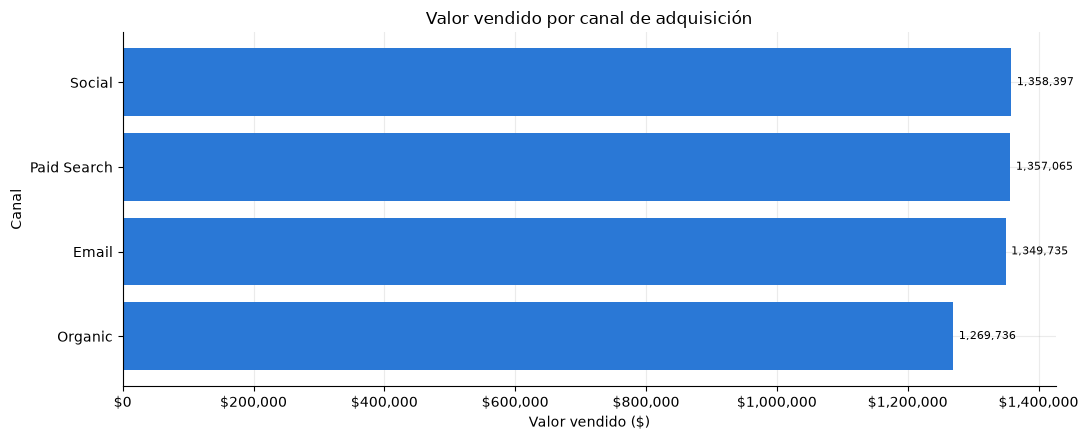

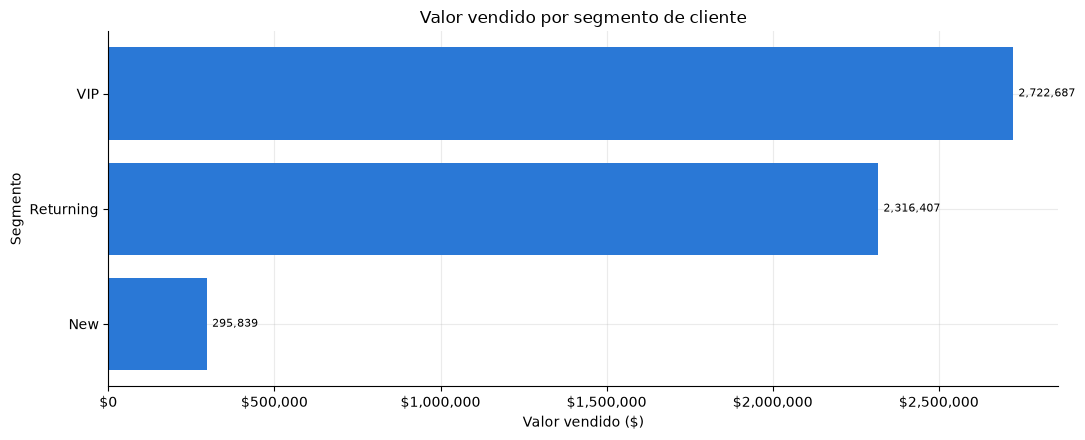

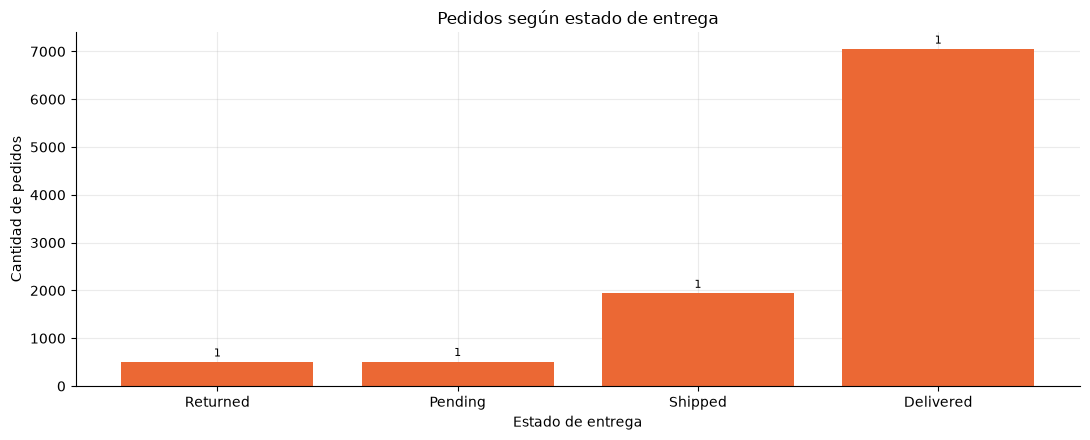

In [47]:
GE.canales()
GE.segmentos()
GE.entregas()

## 4.7 Resumen ejecutivo

Si el LLM está activo, redacta el resumen a partir de las cifras reales; si no, se muestra un resumen calculado con las mismas tablas.

In [48]:
canal = AE.ventas_por_canal()
segmento = AE.ventas_por_segmento()
entregas = AE.estado_entregas()
r = AB.resumen_total()["Empresa"]

cifras = (
    f"Periodo: {AB.periodo()}. Ventas totales: ${r['Ventas totales']:,.2f}. Pedidos: {r['Pedidos']:,.0f}. "
    f"Clientes únicos: {r['Clientes únicos']:,.0f} ({por_cliente['customer_recurrente'].mean():.1%} recurrentes). "
    f"Ticket promedio: ${r['Ticket promedio']:,.2f}. "
    f"Canal con más ventas: {canal.index[0]} ({canal['% ventas'].iloc[0]:.1%}). "
    f"Segmento con más ventas: {segmento.index[0]} ({segmento['% ventas'].iloc[0]:.1%}). "
    f"Pedidos entregados: {entregas.loc['Delivered', 'pedidos'] / entregas['pedidos'].sum():.1%}; "
    f"devueltos: {entregas.loc['Returned', 'pedidos'] / entregas['pedidos'].sum():.1%}. "
    f"Envíos tardíos (más de 3 días): {ventas_enr['delivery_delay'].mean():.1%}."
)

tablas = (
    "VENTAS POR CANAL:\n" + canal[["pedidos", "customers", "ventas", "% ventas"]].round(3).to_string() + "\n\n"
    "VENTAS POR SEGMENTO:\n" + segmento[["pedidos", "customers", "ventas", "% ventas"]].round(3).to_string() + "\n\n"
    "PEDIDOS POR ESTADO DE ENTREGA:\n" + entregas[["pedidos", "ventas"]].round(2).to_string()
)

prompt = ("Eres analista de e-commerce. Escribe en español un resumen ejecutivo de máximo 120 palabras con 3 hallazgos "
          "y 2 recomendaciones. Usa SOLO las cifras de abajo; no calcules ni menciones datos que no aparezcan "
          "(por ejemplo, porcentajes de clientes por segmento). Si las diferencias entre categorías son pequeñas, "
          "dilo en vez de presentarlas como un riesgo.\n\n" + cifras + "\n\n" + tablas)

resumen = llm.generar_texto(prompt)
if resumen is None:
    print("Resumen calculado (sin LLM):\n")
    print(cifras)

**Resumen Ejecutivo (20/04/2024 – 19/04/2025)**

El e-commerce generó **$5.33M** en 10,000 pedidos (ticket $533.49) con 2,713 clientes (79.1% recurrentes).

**Hallazgos:**
1. **Concentración VIP:** El segmento VIP (614 clientes) aporta el **51.0% de ventas** ($2.72M), frente al 43.4% de Returning y 5.5% de New.
2. **Distribución equilibrada por canal:** Social lidera con **25.5%**, pero Paid Search (25.4%), Email (25.3%) y Organic (23.8%) muestran diferencias pequeñas.
3. **Riesgo logístico:** **57.3% de envíos superan 3 días**; solo 70.5% de pedidos están entregados y 5.0% devueltos.

**Recomendaciones:**
1. **Programa de retención VIP** para blindar al 22.6% de clientes que genera la mitad del ingreso.
2. **Optimización urgente de *last-mile*** para reducir envíos tardíos y elevar la tasa de entregados.


## 4.8 Guardar el dataset enriquecido y su reporte

In [49]:
ventas_enr.to_csv("datos/ecommerce_enriquecido.csv", index=False)
reportes = Reportes()
reportes.guardar_reporte(ventas_enr, "reportes/ecommerce_enriquecido.txt")
print("Dataset enriquecido guardado en datos/ecommerce_enriquecido.csv")
print("Reporte guardado en reportes/ecommerce_enriquecido.txt")

Dataset enriquecido guardado en datos/ecommerce_enriquecido.csv
Reporte guardado en reportes/ecommerce_enriquecido.txt
